
# Теория игр и исследование операций
# УПМ-412
# Лабораторная работа №2. Сетевая задача и дискретная оптимизация

# Вариант 1

## Imports

In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
import seaborn as sns

import helpers as h
import importlib
from datetime import datetime
importlib.reload(h)
now = datetime.now()
print(f"Модуль обновлён в {now}")

Модуль обновлён в 2026-10-08 15:33:05.573746


In [2]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 6]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Часть 1. Максимальный поток и минимальный разрез

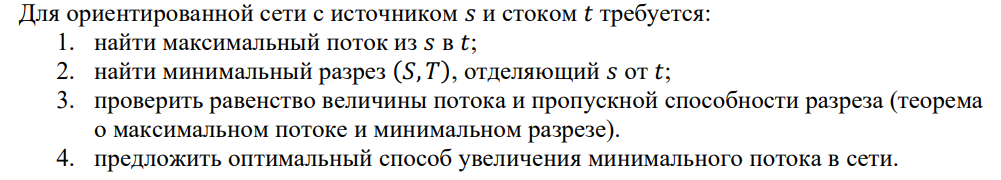

In [3]:
names = ["s", "a", "b", "c", "d", "t"]
edges = [
    ("s", "a"), ("s", "b"), ("a", "c"), ("a", "d"),
    ("b", "c"), ("b", "d"), ("c", "t"), ("d", "t")
]
capacities = [10, 10, 4, 5, 6, 3, 10, 10]

n = len(names)
data = np.zeros((n, n), dtype=int)
for k in range(len(edges)):
    i = names.index(edges[k][0])
    j = names.index(edges[k][1])
    data[i, j] = capacities[k]

data_init = data.copy()
print("Матрица пропускных способностей:")
print(names)
print(data_init)

Матрица пропускных способностей:
['s', 'a', 'b', 'c', 'd', 't']
[[ 0 10 10  0  0  0]
 [ 0  0  0  4  5  0]
 [ 0  0  0  6  3  0]
 [ 0  0  0  0  0 10]
 [ 0  0  0  0  0 10]
 [ 0  0  0  0  0  0]]


### 1.1.1. Перебор разрезов
Разрез — множество S, в котором есть s и нет t. Считаем только дуги, которые идут из множества S во множество T.

In [4]:
cuts = h.all_cuts(data_init)
min_cut_value = cuts[0][1]
print("Минимальная пропускная способность среди всех разрезов:", min_cut_value)

min_cuts = [c for c in cuts if c[1] == min_cut_value]
print("Сколько разрезов с минимальной пропускной способностью:", len(min_cuts))

for c in min_cuts:
    S = [names[i] for i in c[0]]
    T = [names[i] for i in range(n) if i not in c[0]]
    cut_edges = sorted([(names[i], names[j]) for (i, j) in c[2]])
    print("S =", S, "T =", T, "дуги разреза:", cut_edges)

Минимальная пропускная способность среди всех разрезов: 18
Сколько разрезов с минимальной пропускной способностью: 2
S = ['s', 'a', 'b'] T = ['c', 'd', 't'] дуги разреза: [('a', 'c'), ('a', 'd'), ('b', 'c'), ('b', 'd')]
S = ['s', 'a', 'b', 'c'] T = ['d', 't'] дуги разреза: [('a', 'd'), ('b', 'd'), ('c', 't')]


### 1.1.2. Вывод
Минимальная пропускная способность среди всех разрезов равна 18, и таких разрезов два: по дугам {(a,c), (a,d), (b,c), (b,d)} и по дугам {(a,d), (b,d), (c,t)}. Это дуги, которые ограничивают поток: весь поток из s в t обязан пройти через них. В максимальном потоке все эти дуги будут использованы полностью

### 1.2. Максимальный поток

In [5]:
flow, log, residual = h.max_flow(names, data_init, is_print=True)
max_flow_value = flow[0, :].sum()
print("Величина максимального потока:", max_flow_value)

Найден путь: s -> a -> c -> t | delta = 4 | величина потока = 4
Найден путь: s -> a -> d -> t | delta = 5 | величина потока = 9
Найден путь: s -> b -> c -> t | delta = 6 | величина потока = 15
Найден путь: s -> b -> d -> t | delta = 3 | величина потока = 18
Величина максимального потока: 18


### 1.3. Построение графов

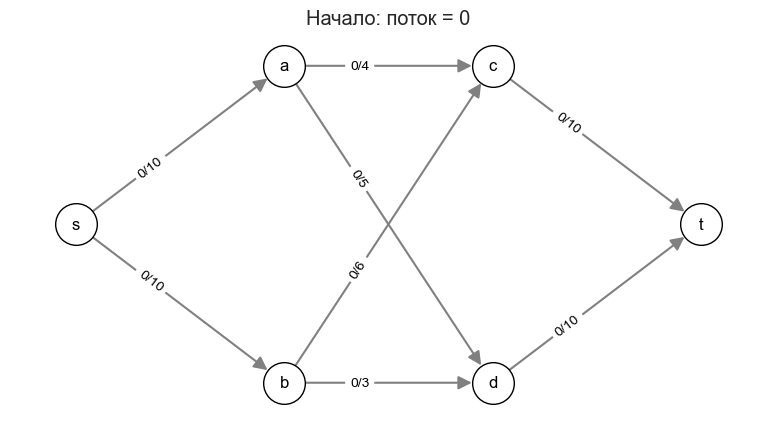

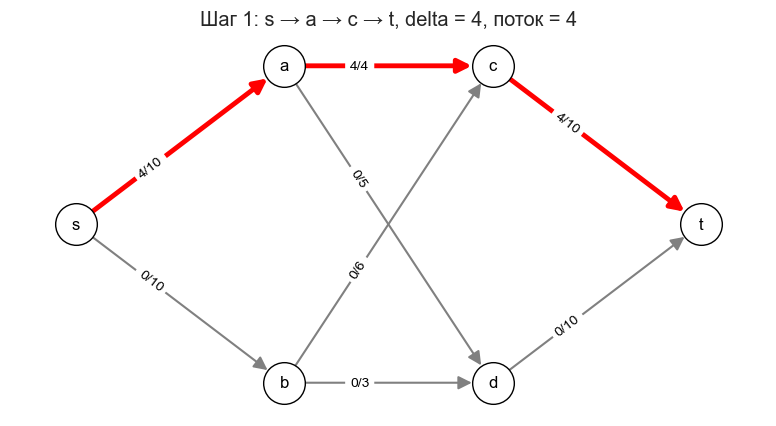

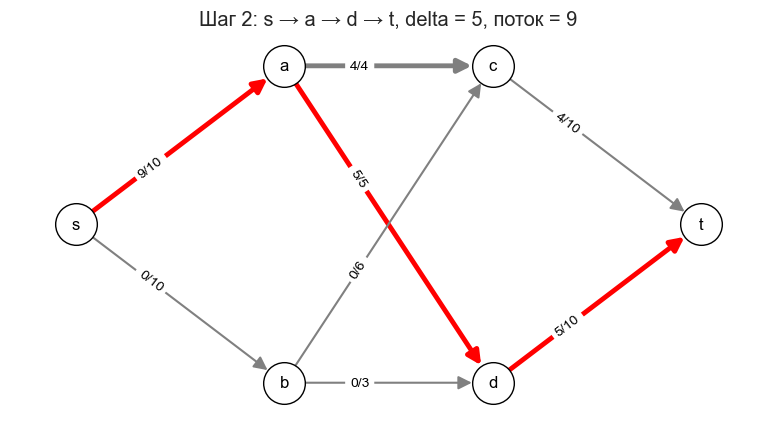

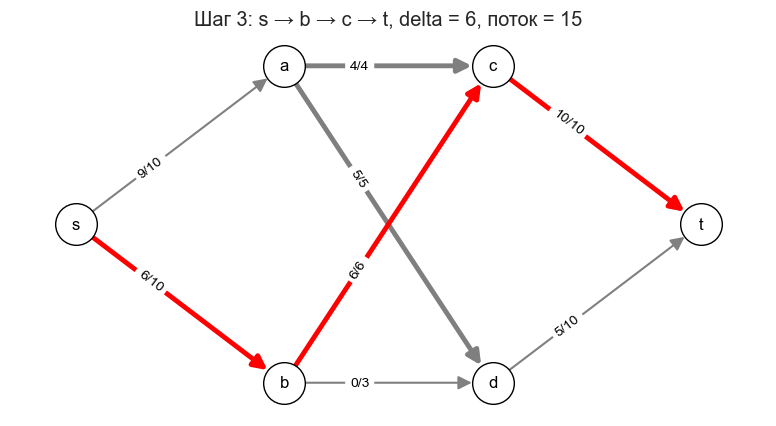

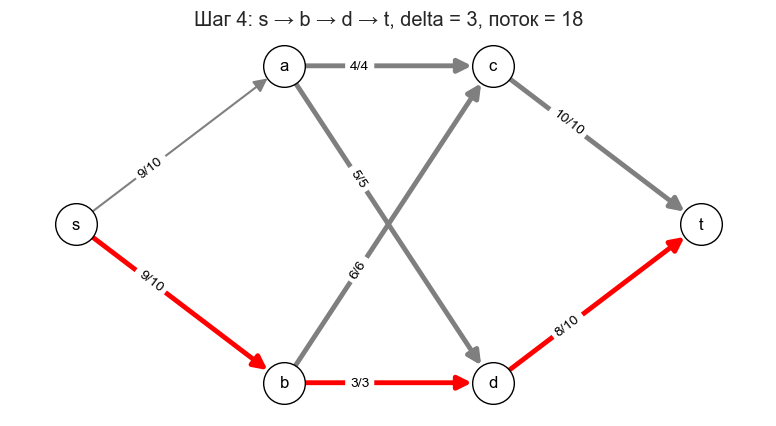

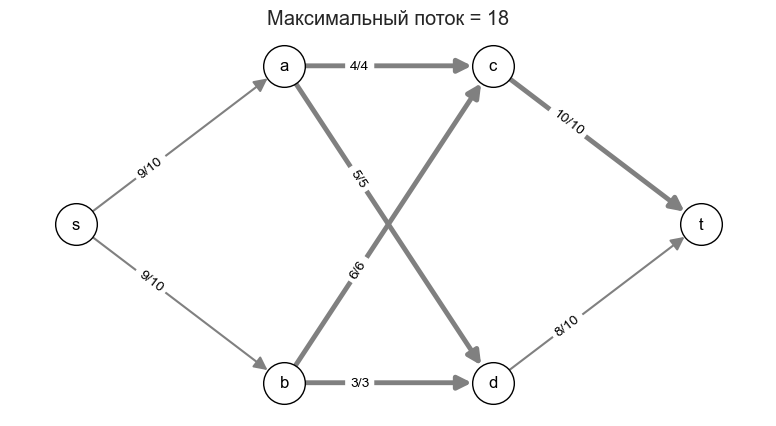

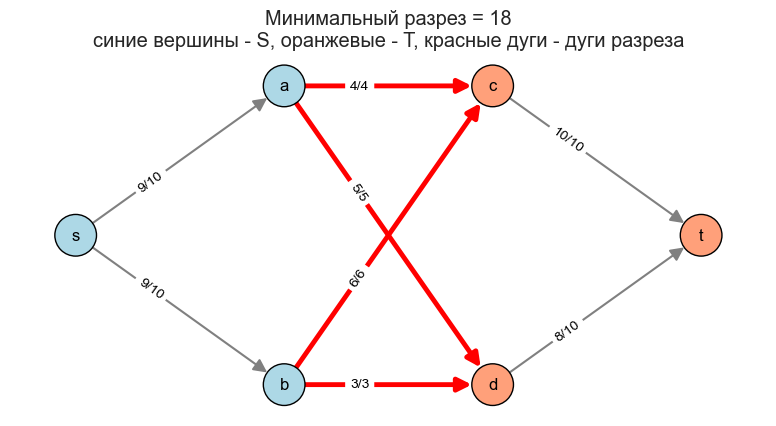

In [6]:
h.plot_flow(names, data_init, log, flow, residual)

### 1.4. Проверка теоремы о максимальном потоке и минимальном разрезе

In [7]:
print("Величина максимального потока:\t", max_flow_value)
print("Минимум по перебору всех разрезов:", min_cut_value)

if max_flow_value == min_cut_value:
    print("Теорема подтверждена: максимальный поток равен пропускной способности минимального разреза")
else:
    print("Допущена ошибка")

Величина максимального потока:	 18
Минимум по перебору всех разрезов: 18
Теорема подтверждена: максимальный поток равен пропускной способности минимального разреза


### 1.5. Оптимальный способ увеличения потока сети

In [8]:
new_data = h.increase_flow(names, data_init)

print("Расширение дуг:")
for i in range(n):
    for j in range(n):
        if new_data[i, j] > data_init[i, j]:
            print(names[i], "->", names[j], ": было", data_init[i, j], ", стало", new_data[i, j],
                  ", расширили на", new_data[i, j] - data_init[i, j])
print("Поток вырос с", h.flow_value(names, data_init), "до", h.flow_value(names, new_data))

Расширение дуг:
a -> d : было 5 , стало 6 , расширили на 1
b -> d : было 3 , стало 4 , расширили на 1
Поток вырос с 18 до 20


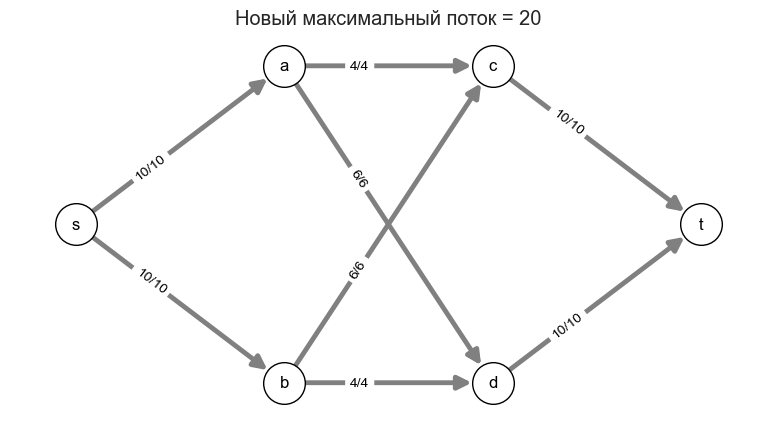

In [9]:
h.plot_new_flow(names, new_data)

### 1.6. Вывод
Максимальный поток равен 18 и совпадает с минимальным разрезом, значит, теорема подтверждена. Узкое место сети — дуги a→d и b→d, общие для обоих минимальных разрезов. Если расширить каждую на 1, поток вырастет до 20

## Часть 2. Числа Фибоначчи
Три метода: рекурсия, мемоизация (рекурсия с кэшем), динамическое программирование.

In [10]:
print("fibonacci(10) =", h.fibonacci(10), "=", h.fibonacci_cache(10, {0: 0, 1: 1}), "=", h.fibonacci_dynamic(10))

fibonacci(10) = 55 = 55 = 55


### 2.1. Замеры

In [11]:
N_rec = list(range(0, 31))
time_rec = []
for N in N_rec:
    t = h.measure(lambda: h.fibonacci(N), 3)
    time_rec.append(t)

sys.setrecursionlimit(10000)
N_fast = list(range(0, 1001, 25))
time_cache = []
time_dyn = []
for N in N_fast:
    t = h.measure(lambda: h.fibonacci_cache(N, {0: 0, 1: 1}), 100, 5)
    time_cache.append(t)
    t = h.measure(lambda: h.fibonacci_dynamic(N), 100, 5)
    time_dyn.append(t)

print("Рекурсия, N = 30:", round(time_rec[-1], 4), "с")
print("Мемоизация, N = 1000:", round(time_cache[-1], 6), "с")
print("Динамика, N = 1000:", round(time_dyn[-1], 6), "с")

Рекурсия, N = 30: 0.4041 с
Мемоизация, N = 1000: 0.000647 с
Динамика, N = 1000: 0.000101 с


In [12]:
# экспоненциальный рост
ratios = []
for k in range(20, len(N_rec)):
    ratios.append(time_rec[k] / time_rec[k - 1])
print("Рекурсия: среднее отношение t(N)/t(N-1) при N от 20 до 30:", round(np.mean(ratios), 3))

# линейный рост
idx_500 = N_fast.index(500)
idx_1000 = N_fast.index(1000)
print("Мемоизация: t(1000)/t(500):", round(time_cache[idx_1000] / time_cache[idx_500], 2))
print("Динамика: t(1000)/t(500):", round(time_dyn[idx_1000] / time_dyn[idx_500], 2))

Рекурсия: среднее отношение t(N)/t(N-1) при N от 20 до 30: 1.6
Мемоизация: t(1000)/t(500): 1.94
Динамика: t(1000)/t(500): 2.09


### 2.2. Графики

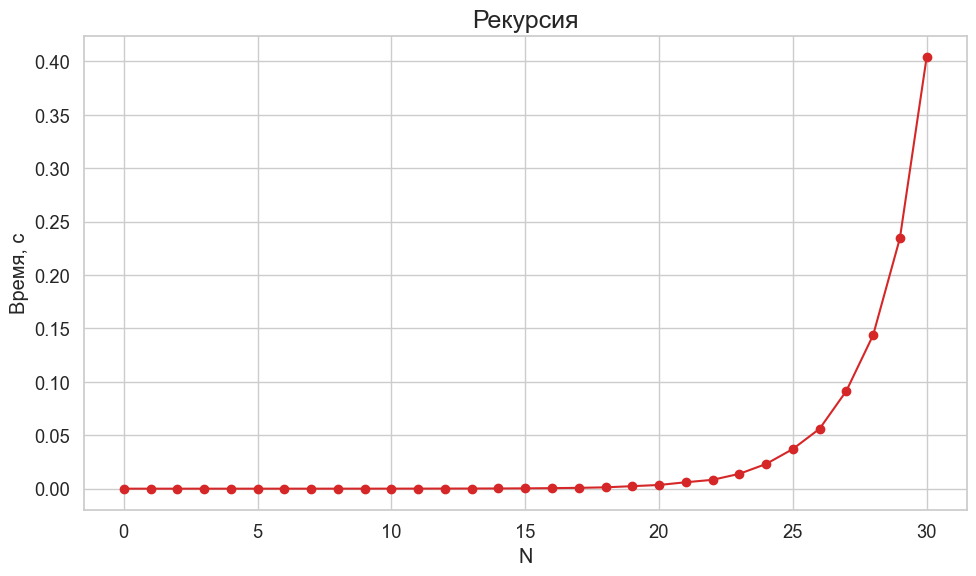

In [13]:
plt.plot(N_rec, time_rec, "o-", color="tab:red")
plt.title("Рекурсия", fontsize=18)
plt.xlabel("N")
plt.ylabel("Время, с")
plt.grid(True)
plt.tight_layout()
plt.show()

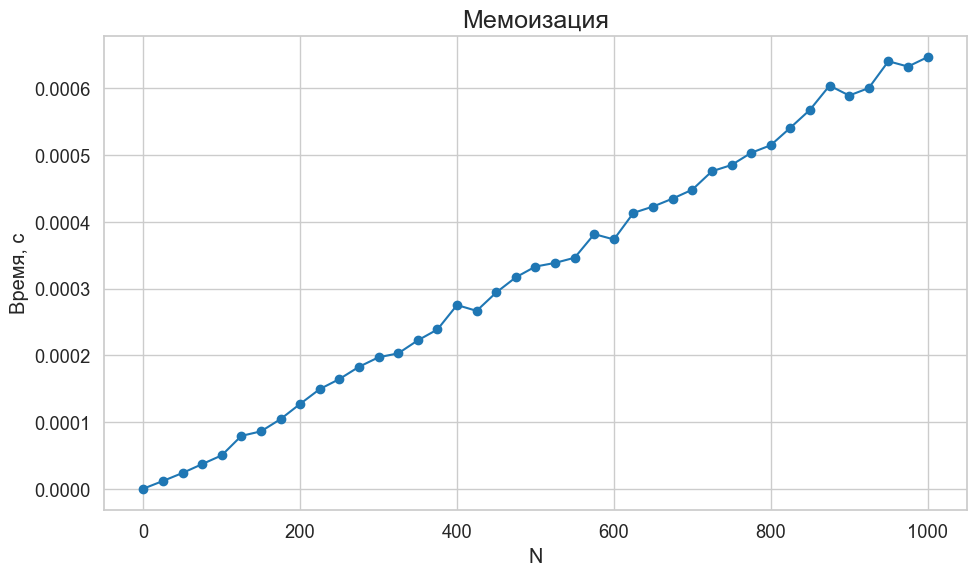

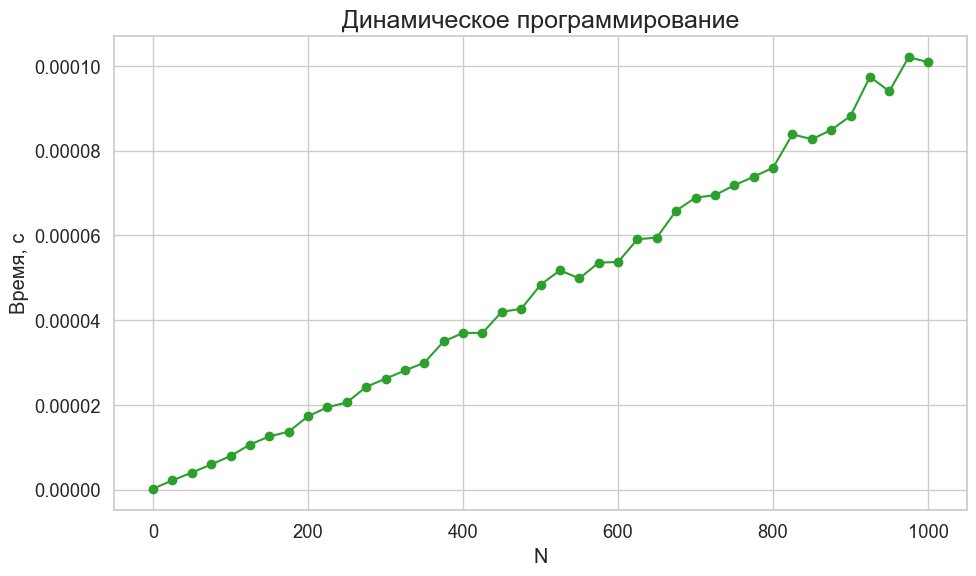

In [14]:
plt.plot(N_fast, time_cache, "o-", color="tab:blue")
plt.title("Мемоизация", fontsize=18)
plt.xlabel("N")
plt.ylabel("Время, с")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.plot(N_fast, time_dyn, "o-", color="tab:green")
plt.title("Динамическое программирование", fontsize=18)
plt.xlabel("N")
plt.ylabel("Время, с")
plt.grid(True)
plt.tight_layout()
plt.show()

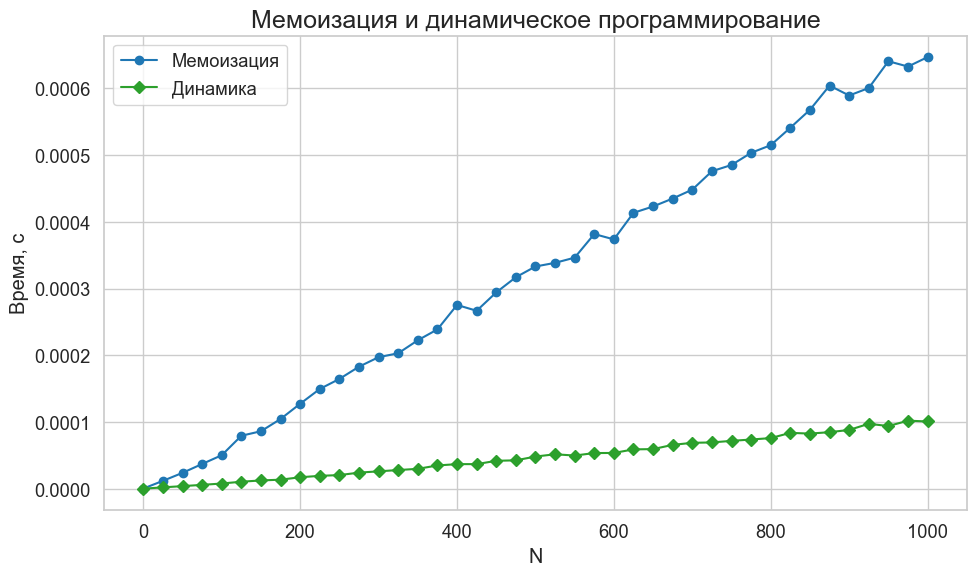

In [15]:
plt.plot(N_fast, time_cache, "o-", color="tab:blue", label="Мемоизация")
plt.plot(N_fast, time_dyn, "D-", color="tab:green", label="Динамика")
plt.title("Мемоизация и динамическое программирование", fontsize=18)
plt.xlabel("N")
plt.ylabel("Время, с")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.3. Вывод
Простая рекурсия много раз пересчитывает одни и те же значения, поэтому её время растёт экспоненциально: при увеличении N на единицу оно растёт примерно в 1,6 раза. Рекурсия с кешем и динамическое программирование считают каждое число один раз, поэтому время растёт линейно и остаётся малым даже при больших N

## Часть 3. Задача о рюкзаке
Жадный и динамический методы

### 3.1. Решение

In [16]:
price = np.array([60, 100, 120, 70, 55, 90])
capacity = np.array([10, 20, 30, 25, 22, 35])
restriction = 50

print("Ценности:", price)
print("Веса    :", capacity)
print("Вместимость:", restriction)
print("Удельная ценность (цена / вес):", np.round(price / capacity, 3))

taken_g, cap_g, price_g = h.backpack_gready(price, capacity, restriction)
print("\nЖадный: Решение", taken_g, "| берём предметы", [i + 1 for i in range(len(taken_g)) if taken_g[i] == 1],
      "| вес", cap_g, "| ценность", price_g)

V, taken_d, price_d, cap_d = h.backpack_dynamic(price, capacity, restriction)
print("Динамика: Решение", taken_d.astype(int), "| берём предметы", [i + 1 for i in range(len(taken_d)) if taken_d[i] == 1],
      "| вес", cap_d, "| ценность", price_d)

print("Абсолютная ошибка жадного алгоритма:", price_d - price_g)
print("Относительная ошибка жадного алгоритма:", round(100 * (price_d - price_g) / price_d, 1), "%")

Ценности: [ 60 100 120  70  55  90]
Веса    : [10 20 30 25 22 35]
Вместимость: 50
Удельная ценность (цена / вес): [6.    5.    4.    2.8   2.5   2.571]

Жадный: Решение [1 1 0 0 0 0] | берём предметы [1, 2] | вес 30 | ценность 160
Динамика: Решение [0 1 1 0 0 0] | берём предметы [2, 3] | вес 50 | ценность 220
Абсолютная ошибка жадного алгоритма: 60
Относительная ошибка жадного алгоритма: 27.3 %


In [17]:
print("Таблица динамического программирования:")
print(V)

Таблица динамического программирования:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  60  60  60  60  60  60  60  60
   60  60  60  60  60  60  60  60  60  60  60  60  60  60  60  60  60  60
   60  60  60  60  60  60  60  60  60  60  60  60  60  60  60]
 [  0   0   0   0   0   0   0   0   0   0  60  60  60  60  60  60  60  60
   60  60 100 100 100 100 100 100 100 100 100 100 160 160 160 160 160 160
  160 160 160 160 160 160 160 160 160 160 160 160 160 160 160]
 [  0   0   0   0   0   0   0   0   0   0  60  60  60  60  60  60  60  60
   60  60 100 100 100 100 100 100 100 100 100 100 160 160 160 160 160 160
  160 160 160 160 180 180 180 180 180 180 180 180 180 180 220]
 [  0   0   0   0   0   0   0   0   0   0  60  60  60  60  60  60  60  60
   60  60 100 100 100 100 100 100 100 100 

### 3.2. Вывод
Жадный алгоритм по отношению ценность/вес быстрый, но не гарантирует оптимум: он берёт самые  по удельному весу предметы,
после чего оставшееся место может не вместить ничего из оставшегося, а лучшее решение может потребовать отказаться от более плотного предмета.
Динамическое программирование всегда находит оптимум, но работает обычно дольше.